# Midterm Exam Graph Data Science 2026/2027 (Neo4j Python Driver and Recommendation)

**Name   :** Naura Kanaya Putri Masruri  
**NIM    :** 24031554138  
**Class  :** INT24

All imports and connection settings live in one cell. The Neo4j password is read from the `NEO4J_PASSWORD` environment variable or typed at a prompt, so no credential is stored in the notebook.

In [32]:
import os, sys, argparse, getpass
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize

import neo4j
from neo4j import GraphDatabase, RoutingControl

URI      = "neo4j://127.0.0.1:7687"
USER     = "neo4j"
PASSWORD = os.environ.get("NEO4J_PASSWORD") or getpass.getpass("Neo4j password: ")
AUTH     = (USER, PASSWORD)
DATA_DIR = "data"

print("Python       :", sys.version.split()[0])
print("neo4j driver :", neo4j.__version__)

Python       : 3.10.19
neo4j driver : 6.4.1


## 1. Environment

```bash
uv venv myvenv --python 3.10
myvenv\Scripts\activate           
uv pip install -r requirements.txt
```

`requirements.txt` pins the packages used here: `neo4j>=5.14`, `pandas`, `numpy`, `scipy`, `scikit-learn`, `networkx`, `matplotlib`, `tqdm`,`ipykernel` and `jupyter`. The Neo4j driver must be version 5.x because `driver.execute_query()` and `RoutingControl`do not exist in driver 4.x.

### **Connection check and list of databases.** 

In [33]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    print("Connected to Neo4j")
    records, _, _ = driver.execute_query("SHOW DATABASES", database_="system")
    for r in records:
        print(f"{r['name']:<10} {r['currentStatus']}")

Connected to Neo4j
neo4j      online
system     online


### **Create nodes and relationships.** 

In [34]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

### **Read the data back.**

In [35]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


#### Result in Neo4j Browser

The query below displays the friendship graph created by `add_friend`:

![Friendship graph](images/friendship_graph.png)

The arrows show that `KNOWS` is directed from Arthur to each friend, and the graph forms an out-star centred on Arthur.

## Checkpoint questions

**1. What is the name of the database used in this tutorial?**

The database used is `neo4j`, which is the default database included with Neo4j. This is evident from the `database_="neo4j"` parameter in the `execute_query` call.

**2. Other ways to access a different database within one instance**

To access a different database within a single instance, simply change the database name in the `database_="dbname"` parameter or create a session using `driver.session(database="dbname")`. In addition to using the Python driver, in Cypher you can use the `USE dbname` command before the query. Meanwhile, database management tasks such as viewing, creating, and deleting are performed via the `system` database using the `SHOW DATABASES`, `CREATE DATABASE`, and `DROP DATABASE` commands.

**3. What kind of friendship graph was created?**

The graph created is a directed graph because the `KNOWS` relationship has a direction from one person to another. This graph is also homogeneous because it has only one type of node (`Person`) and one type of relationship (`KNOWS`), and it is unweighted because the relationships do not carry any values. Its shape resembles a star, with Arthur at the center connected to Guinevere, Lancelot, and Merlin.

In [36]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.execute_query("MATCH (n) DETACH DELETE n", database_="neo4j")
    records, _, _ = driver.execute_query("MATCH (n) RETURN count(n) AS n_nodes", database_="neo4j")
    print("Nodes after reset:", records[0]["n_nodes"])

Nodes after reset: 0


## 2. Part 2.1 (Wrangling and EDA)

### 2.1.1 Period filter (Q1 – Q2)

`events.csv` has five columns: `timestamp` (Unix epoch, **milliseconds**), `visitorid`, `event` (`view`, `addtocart`, `transaction`), `itemid` and `transactionid` (only filled for `transaction`). Using `unit="ms"` in `pd.to_datetime` matters: with seconds the dates would be wrong by decades.

My two periods come from the class spreadsheet (every student has a different combination):

- **P1 (training):** 21 Aug 2015 – 29 Aug 2015
- **P2 (testing):** 30 Aug 2015 – 07 Sep 2015

Both end dates are inclusive (up to 23:59:59.999 UTC). The periods are contiguous but do not overlap and both lie inside the dataset range (3 May – 18 Sep 2015). P1 builds the graph, P2 is kept aside as ground truth for the evaluation.

In [37]:
df = pd.read_csv(os.path.join(DATA_DIR, "events.csv"))
print("Shape:", df.shape)

df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")
print("Date range:", df["datetime"].min(), "->", df["datetime"].max())
df.head()

Shape: (2756101, 5)
Date range: 2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106


In [38]:
P1 = ("2015-08-21", "2015-08-29")  
P2 = ("2015-08-30", "2015-09-07")   

def in_range(d, start, end):
    """Inclusive on both calendar days: [start 00:00:00, end 23:59:59.999]."""
    return (d >= pd.Timestamp(start)) & (d < pd.Timestamp(end) + pd.Timedelta(days=1))

assert pd.Timestamp(P1[1]) < pd.Timestamp(P2[0])
assert df["datetime"].min() <= pd.Timestamp(P1[0]) and pd.Timestamp(P2[1]) <= df["datetime"].max()

df["period"] = None
df.loc[in_range(df["datetime"], *P1), "period"] = "P1"
df.loc[in_range(df["datetime"], *P2), "period"] = "P2"

sub = df[df["period"].notna()].copy()
display(sub.groupby(["period", "event"]).size().unstack(fill_value=0))

sub.to_csv(os.path.join(DATA_DIR, "events_filtered.csv"), index=False)                       # both periods, with helper columns
sub[sub["period"] == "P1"].drop(columns=["datetime", "period"]).to_csv(
    os.path.join(DATA_DIR, "events_p1.csv"), index=False)                                    # input for the Neo4j import
sub[sub["period"] == "P2"].drop(columns=["datetime", "period"]).to_csv(
    os.path.join(DATA_DIR, "events_p2.csv"), index=False)                                    # ground truth for evaluation
print("Saved: events_filtered.csv, events_p1.csv, events_p2.csv")

event,addtocart,transaction,view
period,,,
P1,4157,1305,152082
P2,4053,1259,149816


Saved: events_filtered.csv, events_p1.csv, events_p2.csv


### 2.1.2 Importing P1 into Neo4j

In [39]:
def parse_arguments(argv=None):
    parser = argparse.ArgumentParser(
        description="Import the RetailRocket dataset (events_p1.csv) into Neo4j."
    )
    parser.add_argument("-u", "--user", default="neo4j", help="Neo4j username (default: neo4j)")
    parser.add_argument("-p", "--password", default="neo4j", help="Neo4j password (default: neo4j)")
    parser.add_argument("-b", "--bolt", default="neo4j://127.0.0.1:7687",
                        help="Neo4j URI / Bolt (default: neo4j://127.0.0.1:7687)")
    parser.add_argument("-s", "--source", default="data", help="Data folder (default: data)")
    return parser.parse_args(argv)

args = parse_arguments(["-u", USER, "-p", PASSWORD, "-b", URI, "-s", DATA_DIR])

In [40]:
csv_file_path = os.path.join(args.source, "events_p1.csv")

if not os.path.exists(csv_file_path):
    print(f"Error: file '{csv_file_path}' not found!")
    sys.exit(1)

try:
    driver = GraphDatabase.driver(args.bolt, auth=(args.user, args.password))
    driver.verify_connectivity()
    print("Connected to Neo4j")
except Exception as e:
    print(f"Could not connect to the database: {e}")
    sys.exit(1)

def run_q(query, **params):
    """Run a Cypher query on the 'neo4j' database and return a list of dicts."""
    with driver.session(database="neo4j") as s:
        return s.run(query, **params).data()

def count_rows(path):
    with open(path, encoding="utf-8") as f:
        return sum(1 for _ in f) - 1          # minus the header

Connected to Neo4j


In [41]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL (v, i, row) {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [42]:
n_existing = run_q("MATCH (n) RETURN count(n) AS c")[0]["c"]

if n_existing > 0:
    print(f"The database already contains {n_existing:,} nodes -> import SKIPPED.")
    print("Run the 'Total reset' cell above first if you want a clean re-import.")
else:
    batch_size   = 5000
    total_rows   = count_rows(csv_file_path)
    total_chunks = -(-total_rows // batch_size)            

    with driver.session(database="neo4j") as session:
        create_constraints(session)
        print(f"Reading data from: {csv_file_path}")
        chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

        for chunk in tqdm(chunks, total=total_chunks, desc="Importing batches"):
            # transactionid is NaN except for 'transaction' events -> clean string
            chunk["transactionid"] = (
                chunk["transactionid"].astype("Int64").astype(str).replace("<NA>", "")
            )
            session.execute_write(import_batch, chunk.to_dict(orient="records"))
    print("Import finished.")

Reading data from: data\events_p1.csv


Importing batches: 100%|██████████| 32/32 [00:11<00:00,  2.76it/s]

Import finished.


### 2.1.3 Subgraph composition 

Two Cypher queries describe what the imported subgraph contains:

- `MATCH (n) RETURN labels(n)[0] AS node_type, count(n) AS total ORDER BY total DESC`: `MATCH (n)` binds every node. `labels(n)[0]` returns its label (`Visitor` or `Item`). Because `count(n)` is an aggregate, Neo4j groups implicitly by the non-aggregated column, so we get one count per label. 
- `MATCH ()-[r]->() RETURN type(r) AS relationship_type, count(r) AS total ORDER BY total DESC`: `()-[r]->()` matches every directed relationship whatever its endpoints. `type(r)` returns `VIEWED`, `ADDED_TO_CART` or `BOUGHT`, `count(r)` is grouped by that type. 

The Python API (`session.run(...).data()`) returns a list of dicts that is loaded into DataFrames. As a validation, the number of relationships must equal the number of rows in `events_p1.csv` (one event = one relationship).

In [43]:
q_nodes = "MATCH (n) RETURN labels(n)[0] AS node_type, count(n) AS total ORDER BY total DESC"
q_rels  = "MATCH ()-[r]->() RETURN type(r) AS relationship_type, count(r) AS total ORDER BY total DESC"

df_nodes = pd.DataFrame(run_q(q_nodes))
df_rels  = pd.DataFrame(run_q(q_rels))
df_rels["share"] = (df_rels["total"] / df_rels["total"].sum()).map("{:.1%}".format)
display(df_nodes)
display(df_rels)

n_p1 = count_rows(csv_file_path)
print("Total nodes          :", df_nodes["total"].sum())
print("Total relationships  :", df_rels["total"].sum())
print("Rows in events_p1.csv:", n_p1, "-> match?", df_rels["total"].sum() == n_p1)

,node_type,total
0,Visitor,91525
1,Item,55078


,relationship_type,total,share
0,VIEWED,152082,96.5%
1,ADDED_TO_CART,4157,2.6%
2,BOUGHT,1305,0.8%


Total nodes          : 146603
Total relationships  : 157544
Rows in events_p1.csv: 157544 -> match? True


The subgraph has 146,603 nodes (91,525 `Visitor` and 55,078 `Item`) and 157,544 relationships: 152,082 `VIEWED` (96.5 %), 4,157 `ADDED_TO_CART` (2.6 %) and 1,305 `BOUGHT` (0.8 %).

It is a directed, bipartite graph: edges only go from a `Visitor` to an `Item` and the same pair can have several edges (one per event). Since purchases are rare compared with views, the next section gives each interaction type a different weight.

### 2.1.4 Vector Space Model of Users (Q4)

The bipartite graph is turned into a sparse interaction matrix **R** (users × items). Each cell holds the weighted number of interactions:

`VIEWED = 1`, `ADDED_TO_CART = 3`, `BOUGHT = 5` (the closer to a purchase, the stronger the signal).

- **User VSM:** each row of **R** is one user, a vector in the space whose dimensions are the items.
- **Item VSM:** each row of **Rᵀ** is one item, a vector in the space whose dimensions are the users (section 2.1.5).

The matrix is stored in CSR format, a dense matrix of this size would need tens of gigabytes.

In [44]:
q = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorId AS u, i.itemId AS i, type(r) AS rel, count(*) AS n
"""
edges = pd.DataFrame(run_q(q))
WEIGHTS = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}
edges["w"] = edges["rel"].map(WEIGHTS) * edges["n"]

u_cat = edges["u"].astype("category")
i_cat = edges["i"].astype("category")
user_ids = np.asarray(u_cat.cat.categories)       
item_ids = np.asarray(i_cat.cat.categories)       

R = csr_matrix((edges["w"].values, (u_cat.cat.codes.values, i_cat.cat.codes.values)),
               shape=(len(user_ids), len(item_ids)))      
R_item = R.T.tocsr()                                      

def vsm_stats(M, row_name, col_name):
    per_row = np.diff(M.indptr)
    print(f"Shape               : {M.shape}  ({row_name} x {col_name})")
    print(f"Vector dimension    : {M.shape[1]:,} ({col_name})")
    print(f"Non-zero cells      : {M.nnz:,}")
    print(f"Density             : {M.nnz / (M.shape[0] * M.shape[1]):.6%}")
    print(f"Non-zeros per {row_name:<5}: mean {per_row.mean():.2f} | median {np.median(per_row):.0f} | max {per_row.max()}")
    print(f"{row_name}s with exactly 1 interaction: {(per_row == 1).mean():.1%}")

def plot_sample(M, row_prefix, col_prefix, title, n_rows=12, max_cols=6):
    """networkx plot of the n_rows rows with most non-zeros (and up to max_cols neighbours each)."""
    top = np.argsort(-np.diff(M.indptr))[:n_rows]
    G = nx.Graph()
    for r in top:
        for c in M[r].indices[:max_cols]:
            G.add_edge(f"{row_prefix}{r}", f"{col_prefix}{c}")
    colors = ["tab:blue" if n.startswith(row_prefix) else "tab:orange" for n in G.nodes]
    plt.figure(figsize=(8, 6))
    nx.draw(G, nx.spring_layout(G, seed=42), node_color=colors, node_size=70, width=0.6)
    plt.title(title)
    plt.show()
    print(f"Plotted subgraph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

Shape               : (91525, 55078)  (user x item)
Vector dimension    : 55,078 (item)
Non-zero cells      : 126,174
Density             : 0.002503%
Non-zeros per user : mean 1.38 | median 1 | max 450
users with exactly 1 interaction: 83.4%


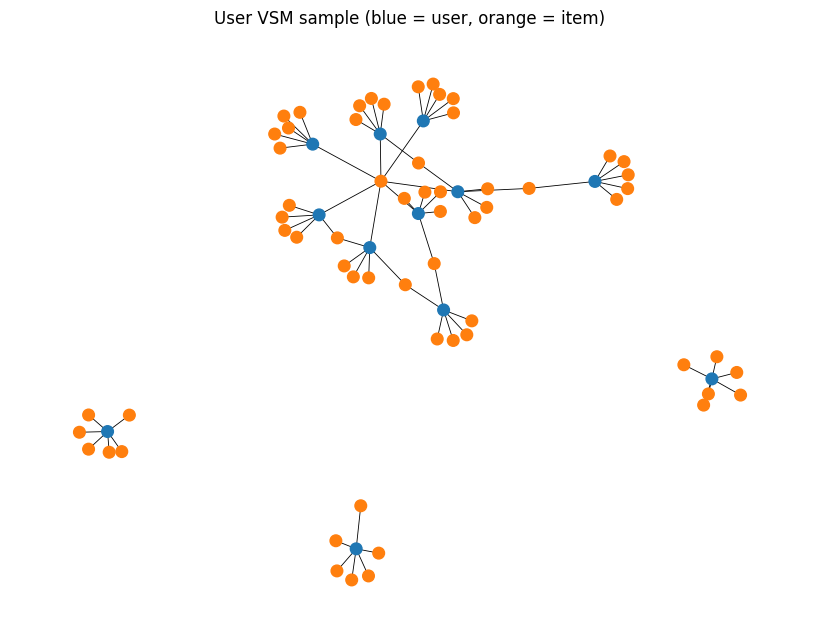

Plotted subgraph: 73 nodes, 72 edges


In [45]:
vsm_stats(R, "user", "item")
plot_sample(R, "U", "I", "User VSM sample (blue = user, orange = item)")

Each user is a vector with 55,078 dimensions (one per item), so the matrix has the shape 91,525 × 55,078. It is extremely sparse: only 126,174 cells are non-zero, a density of 0.0025 %. This is because most users have very short histories. On average a user touched 1.38 distinct items (median 1, maximum 450) and 83.4 % of users touched exactly one item. Two users can only be compared if they share at least one item, so almost all user–user cosine values are 0. The number of non-zero cells (126,174) is lower than the number of relationships (157,544) because repeated events, and different event types on the same user–item pair, are merged into one weighted cell.

The networkx plot shows only the 12 most active users and up to 6 of their items each, so it illustrates the structure around a few hub users, not a typical user.

### 2.1.5 Vector Space Model of Items (Q5)

The Item VSM is the transpose of the User VSM: each item is a vector over users.

Shape               : (55078, 91525)  (item x user)
Vector dimension    : 91,525 (user)
Non-zero cells      : 126,174
Density             : 0.002503%
Non-zeros per item : mean 2.29 | median 1 | max 447
items with exactly 1 interaction: 61.5%


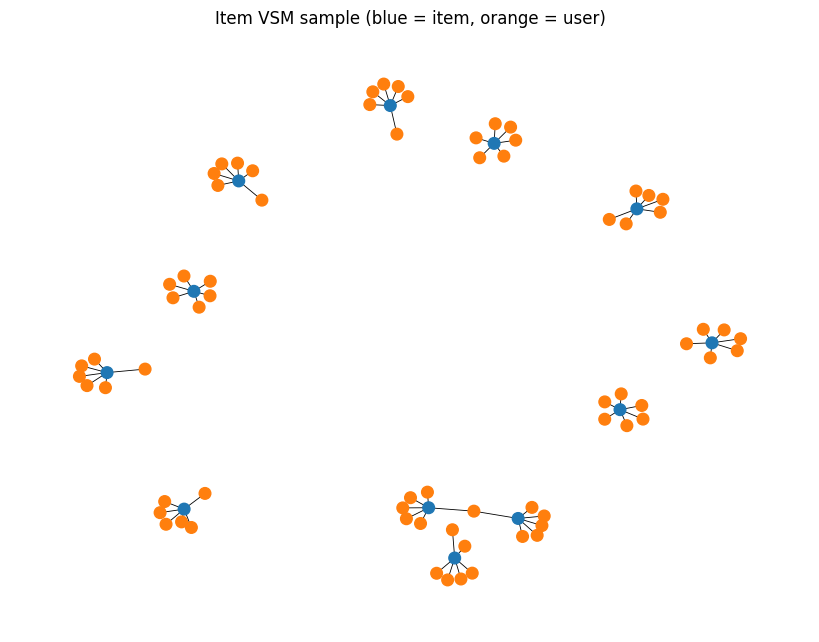

Plotted subgraph: 83 nodes, 72 edges


In [46]:
vsm_stats(R_item, "item", "user")
plot_sample(R_item, "I", "U", "Item VSM sample (blue = item, orange = user)")

The Item VSM is the transpose of the User VSM, so it holds the same 126,174 non-zero cells and the same density of 0.0025 %. Each item is a vector with 91,525 dimensions (one per user), so the matrix has the shape 55,078 × 91,525. Item vectors are somewhat richer than user vectors: an item has 2.29 distinct users on average (median 1, maximum 447) and 61.5 % of items have a single user, compared with 83.4 % of users who have a single item. This means item vectors overlap more often, which makes item–item similarity more informative.

As in the User VSM, the networkx plot uses only the 12 densest rows, so it shows the structure around the most popular items, not a typical item.

### 2.1.6 Which projection is better? (Q6)

- **User–User projection:** two users are connected if they interacted with a common item.
- **Item–Item projection:** two items are connected if a common user interacted with both.

The number of co-interaction pairs (an upper bound on the projection's edges) is computed from the degrees only, without building the full projected matrix: an item with *d* users yields *d(d−1)/2* user pairs, and a user with *d* items yields *d(d−1)/2* item pairs.

In [47]:
deg_item = np.asarray((R > 0).sum(axis=0)).ravel()   
deg_user = np.asarray((R > 0).sum(axis=1)).ravel()   

pairs_user = int((deg_item.astype(np.int64) * (deg_item - 1) // 2).sum())   
pairs_item = int((deg_user.astype(np.int64) * (deg_user - 1) // 2).sum())   

comparison = pd.DataFrame({
    "projection": ["User-User", "Item-Item"],
    "nodes": [R.shape[0], R.shape[1]],
    "co-interaction pairs (edge upper bound)": [pairs_user, pairs_item],
    "dense float64 matrix (GB)": [R.shape[0] ** 2 * 8 / 1e9, R.shape[1] ** 2 * 8 / 1e9],
})
display(comparison.round(2))

PROJ = "item" if pairs_item <= pairs_user else "user"
print("More efficient projection by the numbers:", PROJ.upper() + "-" + PROJ.upper())
print(f"Item-Item has {1 - pairs_item / pairs_user:.1%} fewer candidate edges than User-User")

,projection,nodes,co-interaction pairs (edge upper bound),dense float64 matrix (GB)
0,User-User,91525,550247,67.01
1,Item-Item,55078,526499,24.27


More efficient projection by the numbers: ITEM-ITEM
Item-Item has 4.3% fewer candidate edges than User-User


There are fewer items than users (55,078 against 91,525), so the similarity space is smaller, a dense Item–Item matrix would need about 24 GB, against about 67 GB for User–User. The number of candidate edges is also lower (526,499 against 550,247 co-interaction pairs), but the gap is only about 4 %, so the node count and the signal density matter more than the edge count. Item vectors carry more signal: they have more non-zeros on average (2.29 vs 1.38) and fewer single-interaction rows (61.5 % vs 83.4 %), so item–item similarities are less often zero or based on a single event. Finally, the catalogue changes more slowly than the visitors, so item similarities can be computed once and reused for any user.

The full projected matrix is never built in memory: similarity is computed row by row (one reference vector against all others). All similarity and KNN code below is therefore item-based.

### 2.1.7 Similarity on the projected graph (Q7–Q8)

#### Step 1: graph state before similarity (Q8)

Any previous `SIMILAR_TO` relationships are removed first, so this cell can be re-run and always shows the true "before" state.

In [48]:
run_q("MATCH ()-[s:SIMILAR_TO]->() DELETE s")     # idempotent: always start without similarity edges

before = pd.DataFrame(run_q("MATCH ()-[r]->() RETURN type(r) AS relationship_type, count(r) AS total ORDER BY relationship_type"))
print("BEFORE similarity:")
display(before)

BEFORE similarity:


,relationship_type,total
0,ADDED_TO_CART,4157
1,BOUGHT,1305
2,VIEWED,152082


#### Step 2: top-5 most similar items (Q7a)

Cosine is computed in Python on the Item VSM for the reference item against all other items; the item itself is excluded.

In [49]:
In = normalize(R_item)            

def top_similar(idx, k=5):
    """Indices and cosine scores of the k items most similar to item idx."""
    sims = (In[idx] @ In.T).toarray().ravel()
    sims[idx] = -1                                   
    top = np.argpartition(-sims, k)[:k]
    top = top[np.argsort(-sims[top])]
    return top, sims[top]

ref_idx = int(np.argmax(deg_item))                    
ref_id  = int(item_ids[ref_idx])
nb_idx, nb_sim = top_similar(ref_idx, k=5)
top5 = [(int(item_ids[j]), float(s)) for j, s in zip(nb_idx, nb_sim)]

print("Reference item:", ref_id)
display(pd.DataFrame(top5, columns=["itemId", "cosine"]))

Reference item: 187946


,itemId,cosine
0,284176,0.210688
1,311292,0.204521
2,56100,0.199082
3,22913,0.190575
4,137697,0.189204


#### Step 3: write the scores back into the graph and query them (Q7b)

`UNWIND` iterates over the five (reference, neighbour, score) rows; `MATCH` finds both items through the uniquely
constrained `itemId`; `MERGE` creates the `SIMILAR_TO` relationship once; `SET` stores the cosine value on it.
The second query reads the five relationships back, highest score first.

In [50]:
rows = [{"a": ref_id, "b": b, "score": sc} for b, sc in top5]
run_q("""
UNWIND $rows AS r
MATCH (a:Item {itemId: r.a}), (b:Item {itemId: r.b})
MERGE (a)-[x:SIMILAR_TO]->(b)
SET x.score = r.score
""", rows=rows)

q_top5 = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN b.itemId AS itemId, s.score AS cosine
ORDER BY s.score DESC LIMIT 5
"""
display(pd.DataFrame(run_q(q_top5, ref=ref_id)))

,itemId,cosine
0,284176,0.210688
1,311292,0.204521
2,56100,0.199082
3,22913,0.190575
4,137697,0.189204


#### Step 4: graph state after similarity (Q8)

In [51]:
after = pd.DataFrame(run_q("MATCH ()-[r]->() RETURN type(r) AS relationship_type, count(r) AS total ORDER BY relationship_type"))
print("AFTER similarity:")
display(after)

diff = before.merge(after, on="relationship_type", how="outer", suffixes=("_before", "_after")).fillna(0).astype({"total_before": int, "total_after": int})
display(diff)

AFTER similarity:


,relationship_type,total
0,ADDED_TO_CART,4157
1,BOUGHT,1305
2,SIMILAR_TO,5
3,VIEWED,152082


,relationship_type,total_before,total_after
0,ADDED_TO_CART,4157,4157
1,BOUGHT,1305,1305
2,SIMILAR_TO,0,5
3,VIEWED,152082,152082


#### Graph visualisations (Neo4j Browser)

**Top-5 similarity (Q7).** 

Query that returns the stored scores:

![Top 5 similarity](images/q7_top5_similarity.png)

**Before similarity (Q8).** 

The reference item (187946) and the visitors who interacted with it; no `SIMILAR_TO` edges exist yet:

![Before similarity](images/q8_graph_before_similarity.png)

**After similarity (Q8).** 

The reference item with its five most similar items, connected by `SIMILAR_TO {score}`:

![After similarity](images/q8_graph_after_similarity.png)

## 3. Part 2.2 (Analytics)

### 2.2.1 KNN recommendation for a random user (Q1)

Candidates are users present in the P1 graph who interacted with at least one *new* item in P2 (an item they did not touch in P1), without such an item there would be nothing to evaluate. The candidate list is sorted, and the user is drawn with `numpy.random.default_rng(SEED)` with `SEED = 42`, so the same user is selected on every run.

For each item the user touched (at most the 20 with the largest weight), take its 5 nearest items by cosine similarity. The score of a candidate item is the sum of *(user's weight on the touched item × cosine similarity)*.
Items the user already touched in P1 are excluded.

Most items have very few co-users, so for users with short histories KNN can find fewer than 5 candidates (sometimes only 1). To always return a full list, the remaining slots are filled with the globally most popular P1 items (weighted popularity) that the user has not seen.
Every recommended item is labelled with its source (`KNN` or `popularity`) and the evaluation in 2.2.2 reports KNN-only, hybrid and popularity-only results separately.

The top 5 are used for the metrics, the **3 advertised items** are the first three of this list.

In [52]:
SEED, K, N_REC, N_ADS, MAX_SEEN = 42, 5, 5, 3, 20

p2 = pd.read_csv(os.path.join(DATA_DIR, "events_p2.csv"))
p2_items = p2.groupby("visitorid")["itemid"].apply(lambda s: set(map(int, s))).to_dict()
user_pos = {int(u): k for k, u in enumerate(user_ids)}

def seen_items(u_idx):
    return set(int(x) for x in item_ids[R[u_idx].indices])

def relevant_items(uid):
    """Ground truth: items the user interacted with in P2 but never touched in P1."""
    return p2_items.get(uid, set()) - seen_items(user_pos[uid])

candidates = sorted(u for u in user_pos if u in p2_items)
eligible   = [u for u in candidates if len(relevant_items(u)) > 0]
print("Users in both P1 and P2      :", len(candidates))
print("Eligible (>= 1 new P2 item)  :", len(eligible))

rng        = np.random.default_rng(SEED)
target_id  = int(rng.choice(eligible))
target_idx = user_pos[target_id]
print("Randomly selected user       :", target_id)

Users in both P1 and P2      : 3696
Eligible (>= 1 new P2 item)  : 2502
Randomly selected user       : 142196


In [53]:
pop_score = np.asarray(R.sum(axis=0)).ravel()         
pop_order = np.argsort(-pop_score)

def recommend_knn(u_idx, k=K, n_rec=N_REC, max_seen=MAX_SEEN):
    """Item-based KNN: neighbours (cosine) of the items the user touched, weighted by interaction strength."""
    row    = R[u_idx]
    order  = np.argsort(-row.data)[:max_seen]         
    scores = np.zeros(R.shape[1])
    for pos in order:
        it, w = row.indices[pos], row.data[pos]
        nb, sm = top_similar(it, k=k)                  
        scores[nb] += w * sm
    scores[row.indices] = -np.inf                     
    top = np.argsort(-scores)[:n_rec]
    return [int(item_ids[j]) for j in top if scores[j] > 0]

def popular_items(exclude, n):
    out = []
    for j in pop_order:
        iid = int(item_ids[j])
        if iid not in exclude:
            out.append(iid)
            if len(out) == n:
                break
    return out

def recommend(u_idx, n_rec=N_REC):
    """KNN first; remaining slots (if any) are filled with popular unseen items."""
    knn    = recommend_knn(u_idx)[:n_rec]
    result = [(i, "KNN") for i in knn]
    if len(result) < n_rec:
        exclude = seen_items(u_idx) | set(knn)
        result += [(i, "popularity") for i in popular_items(exclude, n_rec - len(result))]
    return result

In [54]:
history = (pd.DataFrame({"itemId": item_ids[R[target_idx].indices], "weight": R[target_idx].data})
             .sort_values("weight", ascending=False))
print(f"User {target_id}: {len(history)} item(s) touched in P1")
display(history.head(10))

result = recommend(target_idx)
rec_table = pd.DataFrame(result, columns=["itemId", "source"])
rec_table.insert(0, "rank", range(1, len(rec_table) + 1))
print(f"Top-{N_REC} recommendations (k = {K}):")
display(rec_table)

ads = [i for i, _ in result[:N_ADS]]
print(f"\n3 advertised items for user {target_id} (k = {K}):", ads)

User 142196: 1 item(s) touched in P1


,itemId,weight
0,270823,1


Top-5 recommendations (k = 5):


,rank,itemId,source
0,1,273541,KNN
1,2,187946,popularity
2,3,320130,popularity
3,4,461686,popularity
4,5,248455,popularity



3 advertised items for user 142196 (k = 5): [273541, 187946, 320130]


### 2.2.2 Hit@5 and NDCG@5 (Q2)

The metrics are computed on the top-5 list (the 3 advertised items are its first three entries).

**Relevant items** = items the user interacted with in P2 and had not touched in P1.

- **Hit@5** = 1 if at least one of the top-5 items is relevant, otherwise 0.
- **DCG@5** = Σ over relevant items in the list of `1 / log2(rank + 1)`, where rank starts at 1.
- **IDCG@5** = DCG of the ideal ranking (all relevant items first, at most 5).
- **NDCG@5** = DCG@5 / IDCG@5 (0 if there are no relevant items).

First the selected user is evaluated step by step; afterwards the same metrics are averaged over all eligible users to give a more reliable picture than a single user.

In [55]:
def hit_at_k(recs, rel, k=5):
    return int(any(i in rel for i in recs[:k]))

def ndcg_at_k(recs, rel, k=5):
    dcg  = sum(1 / np.log2(pos + 2) for pos, i in enumerate(recs[:k]) if i in rel)
    idcg = sum(1 / np.log2(pos + 2) for pos in range(min(len(rel), k)))
    return dcg / idcg if idcg > 0 else 0.0

rel  = relevant_items(target_id)
recs = [i for i, _ in result]
print(f"User {target_id}: {len(rel)} relevant item(s) in P2")

table = pd.DataFrame({
    "rank":     range(1, len(recs) + 1),
    "itemId":   recs,
    "source":   [s for _, s in result],
    "relevant": [int(i in rel) for i in recs],
})
table["gain = 1/log2(rank+1)"] = np.where(table["relevant"] == 1, 1 / np.log2(table["rank"] + 1), 0.0)
display(table)

print("Hit@5  =", hit_at_k(recs, rel, 5))
print("NDCG@5 =", round(ndcg_at_k(recs, rel, 5), 4))

User 142196: 1 relevant item(s) in P2


,rank,itemId,source,relevant,gain = 1/log2(rank+1)
0,1,273541,KNN,0,0.0
1,2,187946,popularity,0,0.0
2,3,320130,popularity,0,0.0
3,4,461686,popularity,0,0.0
4,5,248455,popularity,0,0.0


Hit@5  = 0
NDCG@5 = 0.0


In [56]:
rows = []
for uid in tqdm(eligible, desc="Evaluating users"):
    u_idx    = user_pos[uid]
    rel_u    = relevant_items(uid)
    res      = recommend(u_idx)
    hybrid   = [i for i, _ in res]
    knn_only = [i for i, s in res if s == "KNN"]
    pop_only = popular_items(seen_items(u_idx), N_REC)
    rows.append({
        "n_knn": len(knn_only),
        "hit_knn": hit_at_k(knn_only, rel_u), "ndcg_knn": ndcg_at_k(knn_only, rel_u),
        "hit_hyb": hit_at_k(hybrid, rel_u),   "ndcg_hyb": ndcg_at_k(hybrid, rel_u),
        "hit_pop": hit_at_k(pop_only, rel_u), "ndcg_pop": ndcg_at_k(pop_only, rel_u),
    })
ev = pd.DataFrame(rows)

summary = pd.DataFrame({
    "method": ["KNN only", "KNN + popularity fill (used above)", "Popularity only (baseline)"],
    "Hit@5":  [ev.hit_knn.mean(),  ev.hit_hyb.mean(),  ev.hit_pop.mean()],
    "NDCG@5": [ev.ndcg_knn.mean(), ev.ndcg_hyb.mean(), ev.ndcg_pop.mean()],
}).round(4)

print(f"Averages over all {len(eligible):,} eligible users")
display(summary)
print(f"KNN returned >= 1 item for {(ev.n_knn >= 1).mean():.1%} of users and a full list of {N_REC} for {(ev.n_knn >= N_REC).mean():.1%}")

Evaluating users: 100%|██████████| 2502/2502 [00:12<00:00, 193.23it/s]

Averages over all 2,502 eligible users


,method,Hit@5,NDCG@5
0,KNN only,0.0296,0.0141
1,KNN + popularity fill (used above),0.0304,0.0143
2,Popularity only (baseline),0.0112,0.0030


KNN returned >= 1 item for 61.4% of users and a full list of 5 for 41.1%


## 4. Summary and limitations

The raw events were filtered into two periods (P1 for training, P2 for testing), and only P1 was imported into Neo4j as `Visitor` and `Item` nodes connected by `VIEWED`, `ADDED_TO_CART` and `BOUGHT` relationships. From this graph I built sparse User and Item vector spaces, chose the Item–Item projection, and wrote cosine similarities back into the graph as `SIMILAR_TO` relationships. These similarities drive an item-based KNN recommender (k = 5), which is evaluated with Hit@5 and NDCG@5 against the P2 data.

The data are extremely sparse: 83.4 % of users have only one interaction in P1, so KNN often finds too few neighbours and the popularity fallback is needed. Each period is only 9 days long, and a "relevant" item is any new item the user interacted with in P2, since 96 % of events are views, relevance is only a weak signal of purchase intent. The interaction weights (1 / 3 / 5) are a modelling choice, not learned from data. Finally, only one random user is shown in detail, so the average over all eligible users is the more reliable figure.

In [57]:
driver.close()
print("Connection closed.")

Connection closed.


The Neo4j driver holds a pool of open connections, so it is closed at the end of the notebook to release them.